In [2]:
#increase the display size to 95% of window width
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))
display(HTML("<style>.output_result { max-width:95% !important; }</style>"))


import os
import sys
import string
import harmonica as hm
import verde as vd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

path = os.getcwd().split('/')
machine_path = '/'+path[1]+'/'+path[2] #cat the /home/user/ or /Users/user from system using path

sys.path.append(f"{machine_path}/opt/post_processing") #functions/mandyocIO.py, if the notebook is not run from post_processing
from functions.mandyocIO import (get_lithology_colors, plot_lithology_legend)

##File of fancy plot style. To use des.mplstyle file you must have an LaTeX distribution in your system
#plt.style.use(machine_path+'/Mestrado/cenarios/mandyoc/scripts_gera_inputs_imgs/new_outputs/des.mplstyle')

In [3]:
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_dz05_Clc10_Cmlit025_Ts0_1080'
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1080'

# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1080'
model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1090'
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1100'

rho0 = xr.open_dataset(f"{model_path}/density.nc", cache=False, engine="h5netcdf")["density"]
T0 = xr.open_dataset(f"{model_path}/temperature.nc", cache=False, engine="h5netcdf")["temperature"]
surface = xr.open_dataset(f"{model_path}/surface.nc", cache=False, engine="h5netcdf")["surface"]
lithology = xr.open_dataset(f"{model_path}/lithology.nc", cache=False, engine="h5netcdf")["lithology"]
strain = xr.open_dataset(f"{model_path}/strain.nc", cache=False, engine="h5netcdf")["strain"]

x = rho0.x.values.astype(float)
z = rho0.z.values.astype(float)
Lx = x[-1]
Lz = z[0]
dz = z[1] - z[0]
dx = x[1] - x[0]
X, Z = np.meshgrid(x, z)

t = 25.0 #Myr
alpha = 3.28e-5 #thermal expansion coefficient

rho_eff = rho0*(1 - alpha*(T0)) #effective density

rho_t = rho_eff.sel(time=t, method="nearest").transpose("z", "x").values
rho0_t = rho0.sel(time=t, method="nearest").transpose("z", "x").values
topo_t = surface.sel(time=t, method="nearest").values
litho_t = lithology.sel(time=t, method="nearest").transpose("z", "x").values
strain_t = strain.sel(time=t, method="nearest").transpose("z", "x").values

drho = rho_t - rho_t[:, [0]] #density contrast (subtracting the density of the first column, which is the reference density)

In [4]:
half_y = x[-1] * 20.0 #half length of the domain in y-direction (northing) and should be 20 times the x-length

#creating prisms
prisms = np.column_stack([
                        X.ravel() - dx / 2, #Return a contiguous flattened array.
                        X.ravel() + dx / 2,
                        np.full(X.size, -half_y), #northing
                        np.full(X.size, half_y), #northing
                        Z.ravel() - dz / 2,
                        Z.ravel() + dz / 2,                        
                        ])

density = drho.ravel()

# topography = z[len(z) - 1 - np.argmax((rho0_t > 100)[::-1], axis=0)]
topography = topo_t
x_aux = np.linspace(0, x[-1], len(topography))

z_obs = float(topography.max()) + 100.0
coords = (x, np.zeros_like(x), np.full_like(x, z_obs))

ge = hm.prism_gravity(coords, prisms, density, field="g_e") #eating component of gravity
gn = hm.prism_gravity(coords, prisms, density, field="g_n") #northing component of gravity
gz = hm.prism_gravity(coords, prisms, density, field="g_z") #upward component of gravity
potential = hm.prism_gravity(coords, prisms, density, field="potential")

/var/folders/ss/gq1wd5111xj_bmqvllgj5zdw0000gn/T/ipykernel_73960/4055321509.py:27: RuntimeWarning: divide by zero encountered in log10
  ax3.imshow(np.log10(np.where(air, 0.0, strain_t)[::-1, :]), extent=(0, Lx/1000, Lz/1000+40, 40), cmap="Greys", vmin=-0.5, vmax=0.9, alpha=0.2, aspect='auto')


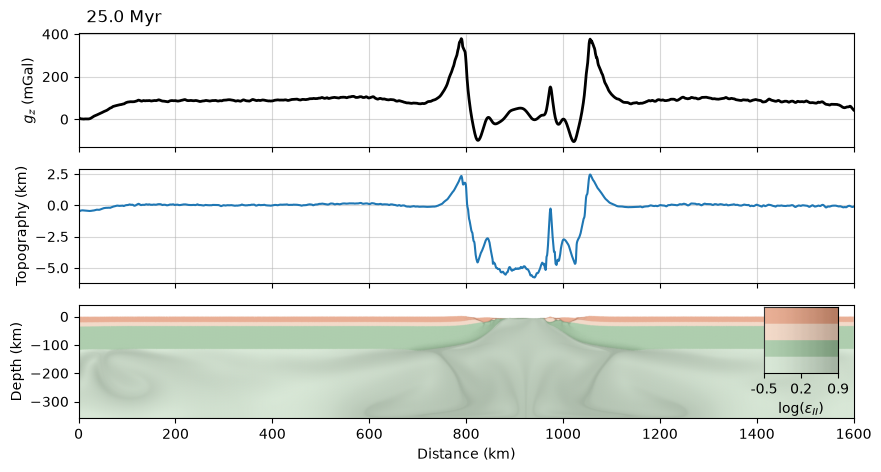

In [5]:
h_air = 40.0e3 #m

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
ax1.plot(x / 1.0e3, gz, color='k', lw=2)
ax2.plot(x_aux / 1.0e3, (topography + h_air) / 1e3)


ax1.text(0.01, 1.1, f"{t:.1f} Myr", transform=ax1.transAxes, fontsize=12, color='k')

ax1.set_ylabel(r"$g_z$ (mGal)")
ax2.set_ylabel("Topography (km)")
ax3.set_ylabel('Depth (km)')
ax3.set_xlabel("Distance (km)")

ax1.set_xlim(0, x[-1] / 1000)

ax1.grid('-k', alpha=0.5)
ax2.grid('-k', alpha=0.5)

lithology_colors = 'auto'
colors = get_lithology_colors(model_path, lithology_colors)
cmap = ListedColormap(colors)

air = rho_t < 1200.0 #tapioca keeps the values in the air: set them to zero there

ax3.imshow(litho_t[::-1, :], aspect='auto', extent=(0, Lx/1000, Lz/1000+40, 40), cmap=cmap, vmin=-0.5, vmax=len(colors)-0.5, alpha=1.0)
ax3.imshow(np.log10(np.where(air, 0.0, strain_t)[::-1, :]), extent=(0, Lx/1000, Lz/1000+40, 40), cmap="Greys", vmin=-0.5, vmax=0.9, alpha=0.2, aspect='auto')

cr = 255.
color_air = (1.,1.,1.) # 5
color_bas = 'xkcd:dark grey blue' #(250./cr,50./cr,50./cr) # 4
color_uc = (228./cr,156./cr,124./cr) # 3
color_lc = (240./cr,209./cr,188./cr) # 2
color_lit = (155./cr,194./cr,155./cr) # 1
color_ast = (207./cr,226./cr,205./cr) # 0
bv1 = plot_lithology_legend(ax3, colors=[color_uc, color_lc, color_lit, color_ast], vmin=-0.5, vmax=0.9, alpha=0.2,
                                        position=(0.98, 0.4), loc='lower right')

(0.0, 1600.0)

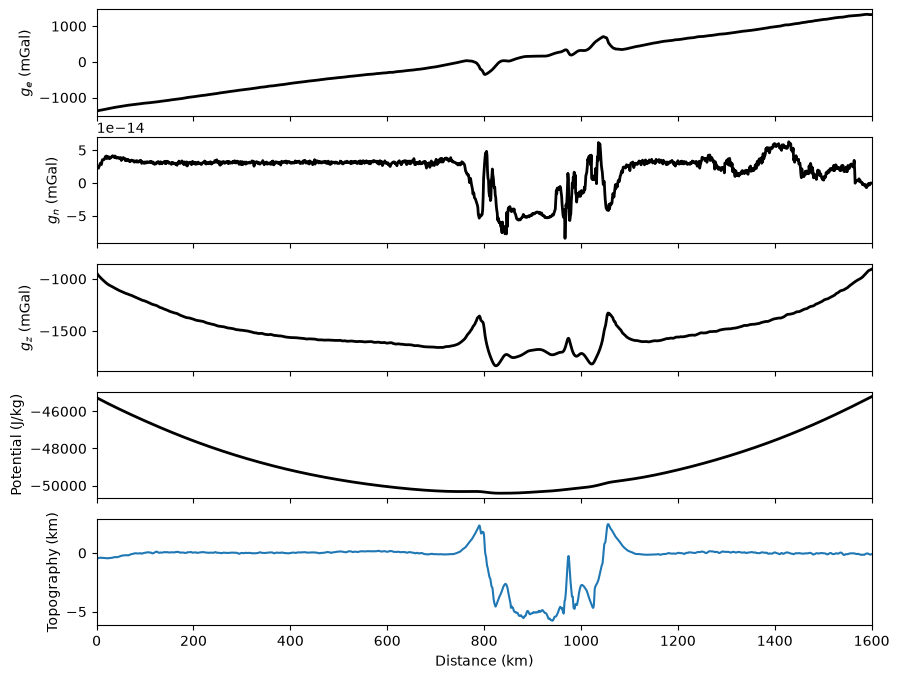

In [13]:
h_air = 40.0e3 #m

fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, 1, figsize=(10, 8), sharex=True)
ax1.plot(x / 1.0e3, ge, color='k', lw=2)
ax2.plot(x / 1.0e3, gn, color='k', lw=2)
ax3.plot(x / 1.0e3, gz, color='k', lw=2)
ax4.plot(x / 1.0e3, potential, color='k', lw=2)
ax5.plot(x_aux / 1.0e3, (topography + h_air) / 1e3)

ax1.set_ylabel(r"$g_e$ (mGal)")
ax2.set_ylabel(r"$g_n$ (mGal)")
ax3.set_ylabel(r"$g_z$ (mGal)")
ax4.set_ylabel("Potential (J/kg)")
ax5.set_ylabel("Topography (km)")
ax5.set_xlabel("Distance (km)")

ax1.set_xlim(0, x[-1] / 1000)